# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

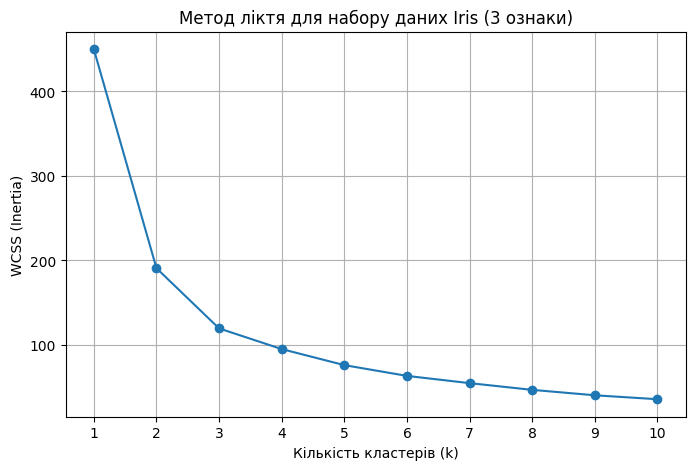

In [ ]:
X_iris = iris_df.iloc[:, :3]

scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_iris_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o')
plt.title('Метод ліктя для набору даних Iris (3 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

k = 2: silhouette_score = 0.5525
k = 3: silhouette_score = 0.4594
k = 4: silhouette_score = 0.4057
k = 5: silhouette_score = 0.3755
k = 6: silhouette_score = 0.3772
k = 7: silhouette_score = 0.3628
k = 8: silhouette_score = 0.3814
k = 9: silhouette_score = 0.3749
k = 10: silhouette_score = 0.3791


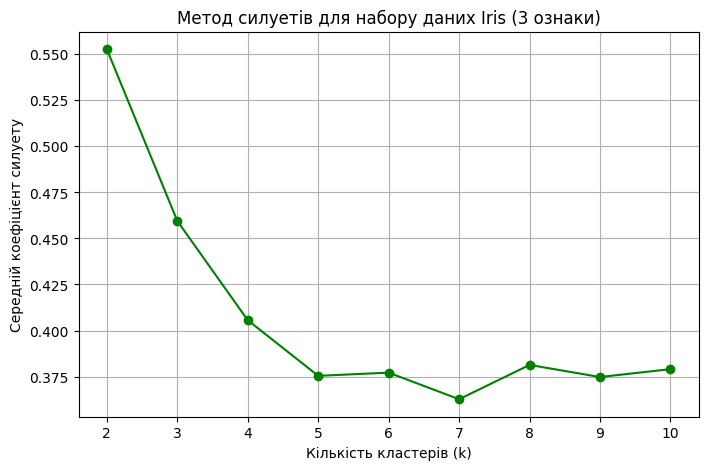

In [ ]:
silhouette_scores = []
k_sil_range = range(2, 11)

for k in k_sil_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_iris_scaled)
    score = silhouette_score(X_iris_scaled, labels)
    silhouette_scores.append(score)
    print(f'k = {k}: silhouette_score = {score:.4f}')

plt.figure(figsize=(8, 5))
plt.plot(k_sil_range, silhouette_scores, marker='o', color='green')
plt.title('Метод силуетів для набору даних Iris (3 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуету')
plt.xticks(k_sil_range)
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

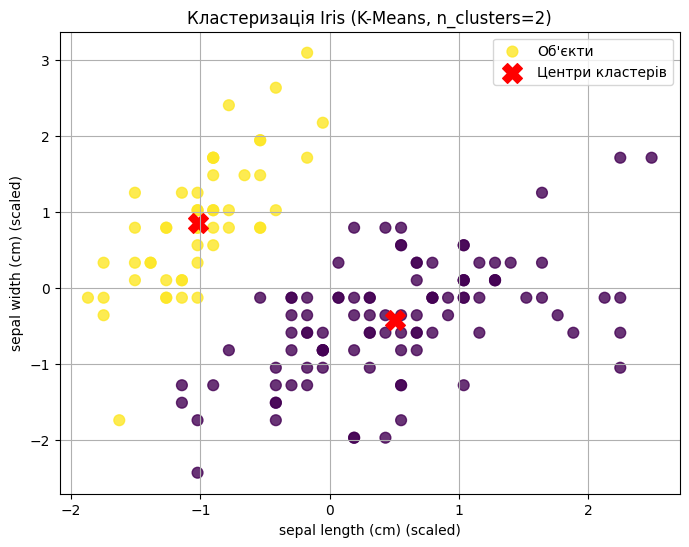

In [ ]:
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(X_iris_scaled)
centers = kmeans_final.cluster_centers_

plt.figure(figsize=(8, 6))
plt.scatter(
    X_iris_scaled[:, 0], X_iris_scaled[:, 1],
    c=clusters, cmap='viridis', s=60, alpha=0.8, label="Об'єкти"
)
plt.scatter(
    centers[:, 0], centers[:, 1],
    c='red', marker='X', s=200, label='Центри кластерів'
)
plt.title('Кластеризація Iris (K-Means, n_clusters=2)')
plt.xlabel(iris.feature_names[0] + ' (scaled)')
plt.ylabel(iris.feature_names[1] + ' (scaled)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Висновок:

За графіком методу ліктя найбільш різке зниження суми квадратів відстаней (WCSS) спостерігається при переході від 1 до 2 кластерів, після чого спадання стає помітно повільнішим (другий, менш виражений згин — на 3 кластерах). Метод силуетів дає максимальне значення коефіцієнта силуету саме для k = 2, що свідчить про найкращу геометричну відокремленість двох кластерів. Вибір n_clusters=2 повністю узгоджується з обома графіками: у просторі трьох ознак один вид ірисів (Setosa) чітко відділяється від двох інших (Versicolor і Virginica), які частково перекриваються між собою.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір X_train:", X_train_scaled.shape)
print("Розмір X_test:", X_test_scaled.shape)

Розмір X_train: (1913, 13)
Розмір X_test: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)

print("Найкращі параметри Random Forest:", rf_grid.best_params_)
print(f"Середня CV-точність: {rf_grid.best_score_:.4f}")
print(f"Тестова accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

Найкращі параметри Random Forest: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9211
Тестова accuracy: 0.9102

Classification Report:
               precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
lr_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2']
}

lr_grid = GridSearchCV(
    LogisticRegression(solver='saga', max_iter=5000, random_state=42),
    param_grid=lr_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

best_lr = lr_grid.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)

print("Найкращі параметри Logistic Regression:", lr_grid.best_params_)
print(f"Середня CV-точність: {lr_grid.best_score_:.4f}")
print(f"Тестова accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")

Найкращі параметри Logistic Regression: {'C': 0.1, 'penalty': 'l1'}
Середня CV-точність: 0.8024
Тестова accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
svm_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    SVC(random_state=42),
    param_grid=svm_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
svm_grid.fit(X_train_scaled, y_train)

best_svm = svm_grid.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)

print("Найкращі параметри SVM:", svm_grid.best_params_)
print(f"Середня CV-точність: {svm_grid.best_score_:.4f}")
print(f"Тестова accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")

Найкращі параметри SVM: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8547
Тестова accuracy: 0.8497


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
models_results = {
    'Random Forest': (rf_grid.best_score_, accuracy_score(y_test, y_pred_rf), y_pred_rf),
    'Logistic Regression': (lr_grid.best_score_, accuracy_score(y_test, y_pred_lr), y_pred_lr),
    'SVM': (svm_grid.best_score_, accuracy_score(y_test, y_pred_svm), y_pred_svm)
}

for name, (cv_acc, test_acc, _) in models_results.items():
    print(f"{name:20s} | CV-точність: {cv_acc:.4f} | Тестова accuracy: {test_acc:.4f}")

best_model_name = max(models_results, key=lambda k: models_results[k][0])
best_preds = models_results[best_model_name][2]

print(f"\nНайкраща модель за CV-точністю: {best_model_name}")
print("\nClassification Report на тестових даних:\n")
print(classification_report(y_test, best_preds))

Random Forest        | CV-точність: 0.9211 | Тестова accuracy: 0.9102
Logistic Regression  | CV-точність: 0.8024 | Тестова accuracy: 0.8184
SVM                  | CV-точність: 0.8547 | Тестова accuracy: 0.8497

Найкраща модель за CV-точністю: Random Forest

Classification Report на тестових даних:

              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

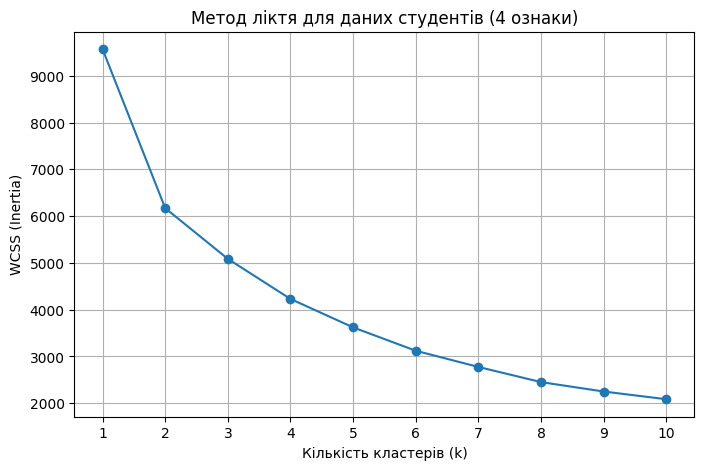

In [ ]:
features_4 = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_stud_4 = df[features_4]

scaler_stud_4 = StandardScaler()
X_stud_4_scaled = scaler_stud_4.fit_transform(X_stud_4)

wcss_stud = []
k_range_stud = range(1, 11)

for k in k_range_stud:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_stud_4_scaled)
    wcss_stud.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range_stud, wcss_stud, marker='o')
plt.title('Метод ліктя для даних студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range_stud)
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

k = 2: silhouette_score = 0.3080
k = 3: silhouette_score = 0.2702
k = 4: silhouette_score = 0.2580
k = 5: silhouette_score = 0.2645
k = 6: silhouette_score = 0.2689
k = 7: silhouette_score = 0.2692
k = 8: silhouette_score = 0.2712
k = 9: silhouette_score = 0.2732
k = 10: silhouette_score = 0.2725


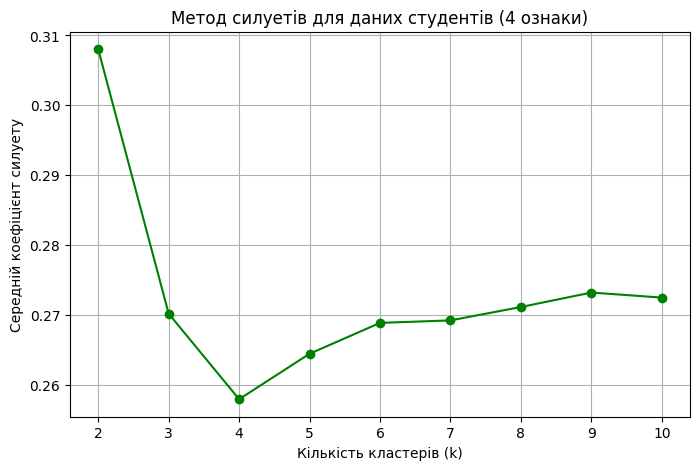

In [ ]:
sil_stud = []
k_sil_stud = range(2, 11)

for k in k_sil_stud:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_stud_4_scaled)
    score = silhouette_score(X_stud_4_scaled, labels)
    sil_stud.append(score)
    print(f"k = {k}: silhouette_score = {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_sil_stud, sil_stud, marker='o', color='green')
plt.title('Метод силуетів для даних студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуету')
plt.xticks(k_sil_stud)
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
X_pca_raw = df.drop(columns=['StudentID', 'GradeClass'])
X_pca_raw.head()

,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA
0,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196
1,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915
2,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602
3,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218
4,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_raw)

pca_full = PCA()
pca_full.fit(X_pca_scaled)

explained_variance = pca_full.explained_variance_ratio_
for i, var in enumerate(explained_variance, start=1):
    print(f"Компонента {i}: {var:.4f}")

Компонента 1: 0.1525
Компонента 2: 0.0861
Компонента 3: 0.0827
Компонента 4: 0.0807
Компонента 5: 0.0786
Компонента 6: 0.0779
Компонента 7: 0.0763
Компонента 8: 0.0760
Компонента 9: 0.0744
Компонента 10: 0.0738
Компонента 11: 0.0717
Компонента 12: 0.0675
Компонента 13: 0.0018


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Знайдена точка ліктя (кількість компонент): 2


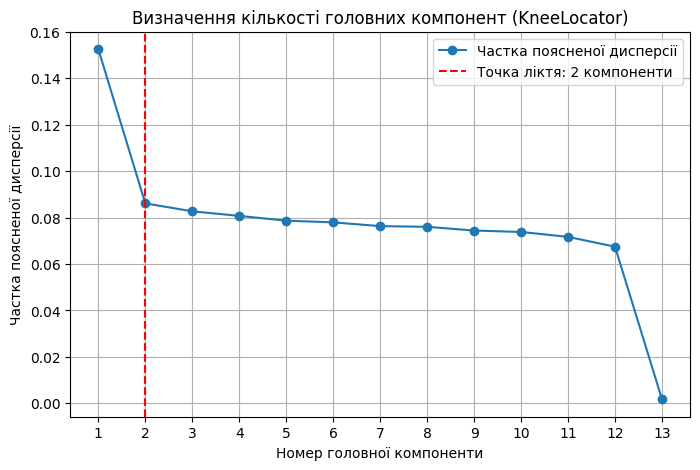

In [ ]:
components_axis = range(1, len(explained_variance) + 1)
kl = KneeLocator(components_axis, explained_variance, curve='convex', direction='decreasing')
n_components = kl.elbow

print(f"Знайдена точка ліктя (кількість компонент): {n_components}")

plt.figure(figsize=(8, 5))
plt.plot(components_axis, explained_variance, marker='o', label='Частка поясненої дисперсії')
if n_components is not None:
    plt.axvline(x=n_components, color='red', linestyle='--', label=f'Точка ліктя: {n_components} компоненти')
plt.title('Визначення кількості головних компонент (KneeLocator)')
plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(components_axis)
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Фактична кумулятивна частка дисперсії для 2 компонент: 0.2386 (23.86%)


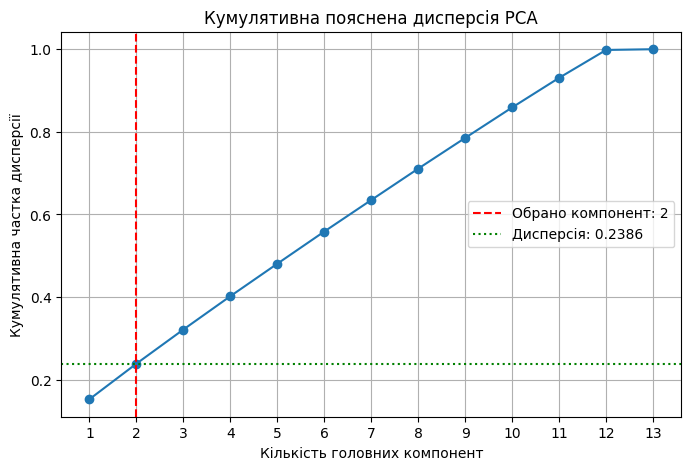

Розмірність даних після PCA: (2392, 2)


In [ ]:
cumulative_variance = np.cumsum(explained_variance)

n_comp = n_components if n_components is not None else 2
actual_cum_var = cumulative_variance[n_comp - 1]

print(f"Фактична кумулятивна частка дисперсії для {n_comp} компонент: {actual_cum_var:.4f} ({actual_cum_var*100:.2f}%)")

plt.figure(figsize=(8, 5))
plt.plot(components_axis, cumulative_variance, marker='o')
plt.axvline(x=n_comp, color='red', linestyle='--', label=f'Обрано компонент: {n_comp}')
plt.axhline(y=actual_cum_var, color='green', linestyle=':', label=f'Дисперсія: {actual_cum_var:.4f}')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(components_axis)
plt.legend()
plt.grid(True)
plt.show()

pca = PCA(n_components=n_comp)
X_pca = pca.fit_transform(X_pca_scaled)
print("Розмірність даних після PCA:", X_pca.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

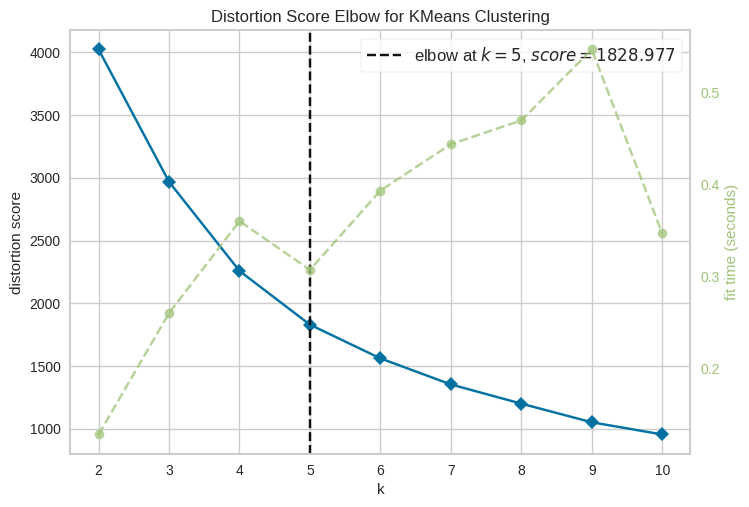

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
model_km = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model_km, k=(2, 11))
visualizer.fit(X_pca)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.
##Висновок

У ході роботи було досліджено методи визначення оптимальної кількості кластерів (метод ліктя, коефіцієнт силуету та автоматичний KElbowVisualizer). Метод ліктя оцінює швидкість зменшення внутрішньокластерної суми квадратів (WCSS) і часто має суб'єктивний згин, тоді як коефіцієнт силуету кількісно вимірює відокремленість кластерів, а KElbowVisualizer автоматизує пошук точки ліктя.

У завданні 2 чітко видно різницю між класифікацією та кластеризацією: класифікація (навчання з учителем) використовує цільову змінну GradeClass для прогнозування класу успішності студента (найкращу CV-точність показала модель Random Forest), тоді як кластеризація (навчання без учителя) не використовує GradeClass, а самостійно групує студентів за схожістю їхніх числових ознак.

За допомогою PCA та KneeLocator було обрано 2 головних компонент, які разом пояснюють 23.86% загальної дисперсії даних, після чого KElbowVisualizer визначив оптимальну кількість кластерів у просторі головних компонент (k = 5).